# GQA data preparation for mobile-VLM distillation (v2)

**Run on CPU (Accelerator = None).** No GPU quota is used.

**Attach only two datasets:** `GQA Images` and `GQA Questions`.
The Object Features, Spatial Features and Scene graph datasets are not used (different encoder / not needed), so detach them.

What this notebook produces in `/kaggle/working/gqa_v2_seed42/`:

| File | Purpose |
|---|---|
| `train_{N}.json` | one question per record (single-turn). Use for teacher caching, ablations, token-compression training |
| `train_{N}_packed.json` | all questions of one image packed into multi-turn records: the vision encoder runs once per image (about 5-10x cheaper) |
| `dev.json`, `dev_mini.json` | validation (from val_balanced, single-turn) |
| `testdev.json` | final test (testdev_balanced, single-turn). Untouched until the end |
| `images/` | only the sampled images, verified |
| `answer_vocab.json` | answer frequencies from the full train split |
| `gqa_utils.py` | `GQADataset`, answer normalisation, evaluator with per-type accuracy |
| `stats.json`, `eda.png`, `README.md` | reproducibility record |

## 1. Config

GQA balanced train has about 13 questions/image. Sizing for 2x T4 and about 30 GPU h/week:

| Tier (images) | ~Questions | Use |
|---|---|---|
| 2,000 | 26K | pipeline debugging |
| 5,000 | 65K | fast loss ablations |
| **10,000** | **130K** | **main experiments** |
| 20,000 | 260K | final / scale-up run |

Packed records cut the number of image forward passes from about 13 per image to about 2, so the larger tiers stay affordable.

In [1]:
CFG = dict(
    seed=42,
    version="v2_seed42",
    train_tiers=[2000, 5000, 10000, 20000],   # nested prefixes of one shuffled list
    dev_images=1000,                          # from val_balanced (about 13K questions)
    dev_mini_images=300,                      # subset of dev, for quick checks inside training
    max_q_per_image=None,                     # None = keep all balanced questions of a sampled image
    pack_turns=6,                             # max questions per packed multi-turn record
    resize_max_side=None,                     # None = keep original pixels (GQA images are about 500x375)
    suffix="\nAnswer the question using a single word or phrase.",
    out_dir="/kaggle/working/gqa_v2_seed42",
    n_workers=8,
)

## 2. Setup and discovery of the two datasets
One depth-limited walk over `/kaggle/input` finds the three question files and indexes the images by image id.
The feature folders are skipped, so the walk stays fast even if you left them attached.

In [2]:
import os, sys, json, random, shutil, time, collections, gc
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

SEED = CFG["seed"]
OUT = Path(CFG["out_dir"]); IMG_OUT = OUT / "images"
OUT.mkdir(parents=True, exist_ok=True); IMG_OUT.mkdir(exist_ok=True)

Q_NAMES = {"train": "train_balanced_questions.json", "val": "val_balanced_questions.json",
           "testdev": "testdev_balanced_questions.json"}
INV = {v: k for k, v in Q_NAMES.items()}
SKIP = ("gqa_objects", "objects", "spatial", "train_all_questions")

base = Path("/kaggle/input"); Q_FILES, IMG_INDEX = {}, {}
t = time.time()
for dp, dn, fn in os.walk(base):
    depth = len(Path(dp).parts) - len(base.parts)
    dn[:] = [d for d in dn if not d.startswith(SKIP)] if depth < 4 else []
    for f in fn:
        if f in INV: Q_FILES[INV[f]] = os.path.join(dp, f)
        elif f.lower().endswith((".jpg", ".jpeg", ".png")): IMG_INDEX[Path(f).stem] = os.path.join(dp, f)
print(f"Discovery took {time.time()-t:.0f}s")
print("Question files:", json.dumps(Q_FILES, indent=1))
print(f"Images indexed: {len(IMG_INDEX):,}  e.g. {next(iter(IMG_INDEX.items()))}")
assert set(Q_FILES) == set(Q_NAMES), f"missing question files: {set(Q_NAMES) - set(Q_FILES)} (attach 'GQA Questions')"
assert len(IMG_INDEX) > 1000, "no images found (attach 'GQA Images')"
if len(IMG_INDEX) < 100_000: print("WARNING: fewer than 113K images indexed, some questions will be dropped")

Discovery took 159s
Question files: {
 "val": "/kaggle/input/datasets/ammarmasselhy/gqa-questions/val_balanced_questions.json",
 "train": "/kaggle/input/datasets/ammarmasselhy/gqa-questions/train_balanced_questions.json",
 "testdev": "/kaggle/input/datasets/ammarmasselhy/gqa-questions/testdev_balanced_questions.json"
}
Images indexed: 148,854  e.g. ('2346156', '/kaggle/input/datasets/ammarmasselhy/gqa-20gb/images/2346156.jpg')


## 3. Load balanced questions
Only the needed fields are kept (the functional program and group info are dropped to save RAM).
Questions whose image is missing are removed.

In [3]:
def load_split(split):
    t = time.time()
    with open(Q_FILES[split]) as f: raw = json.load(f)
    out = {}
    for qid, q in raw.items():
        out[qid] = dict(question=q["question"], answer=q["answer"], fullAnswer=q.get("fullAnswer", ""),
                        imageId=q["imageId"], structural=q["types"]["structural"], semantic=q["types"]["semantic"])
    del raw; gc.collect()
    n0 = len(out)
    out = {k: v for k, v in out.items() if v["imageId"] in IMG_INDEX}
    print(f"{split:8s}: {n0:,} questions, {len(out):,} with an image ({time.time()-t:.0f}s)")
    return out

QS = {s: load_split(s) for s in Q_NAMES}

train   : 943,000 questions, 943,000 with an image (35s)
val     : 132,062 questions, 132,062 with an image (5s)
testdev : 12,578 questions, 12,578 with an image (0s)


## 4. Inspect

train {'n_questions': 943000, 'n_images': 72140, 'q_per_image': 13.07}
val {'n_questions': 132062, 'n_images': 10234, 'q_per_image': 12.9}
testdev {'n_questions': 12578, 'n_images': 398, 'q_per_image': 31.6}

Structural (train): {'verify': '20.7%', 'query': '51.7%', 'choose': '12.3%', 'logical': '12.1%', 'compare': '3.1%'}
Semantic   (train): {'attr': '31.8%', 'rel': '46.5%', 'obj': '11.8%', 'cat': '6.7%', 'global': '3.1%'}

1,833 distinct answers; top 15: [('no', 166217), ('yes', 165681), ('left', 49009), ('right', 48342), ('man', 11642), ('white', 11546), ('black', 10107), ('bottom', 9033), ('woman', 8604), ('chair', 8403), ('blue', 8243), ('top', 8021), ('table', 7267), ('brown', 7115), ('boy', 6571)]
yes/no share of all questions: 35.2%
Question words: mean 8.8, p95 16 | answer words: mean 1.03, max 3
Image size (300 sampled): median 500x375, largest side 1024


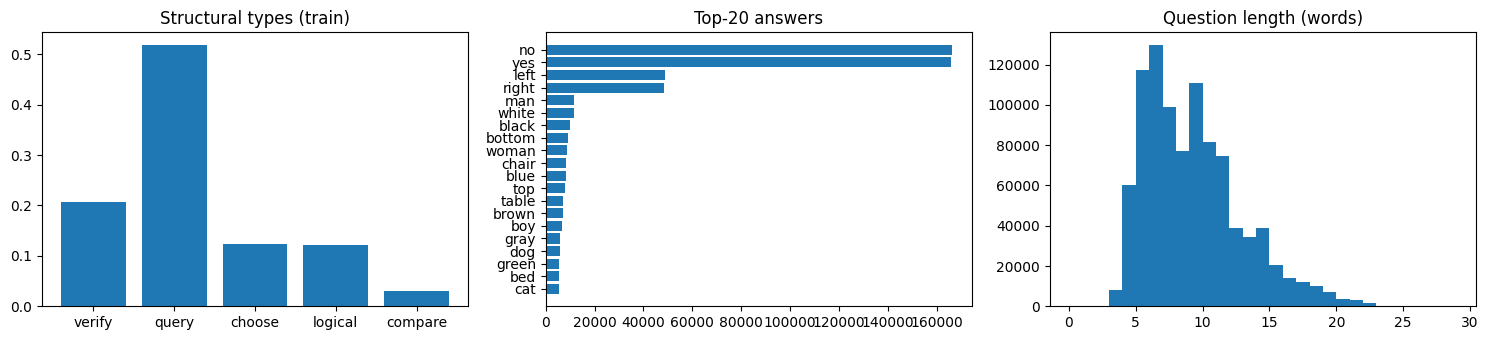


--- 12 random examples (read by eye) ---
[query   ] Who is holding the spoon to the left of the man?  ->  people   (img 2373944)
[query   ] On which side is the gold curtain?  ->  left   (img 2387451)
[compare ] Is the cabinet the same material as the frame?  ->  no   (img 2403549)
[choose  ] Is the rope in the top or in the bottom part?  ->  bottom   (img 2411676)
[query   ] Which kind of animal is it?  ->  cat   (img 2369731)
[query   ] Where is the person?  ->  bakery   (img 2373188)
[verify  ] Does the racket to the right of the man look large?  ->  no   (img 2370907)
[verify  ] Is the truck that is to the left of the cone parked at the gas pump?  ->  yes   (img 2356921)
[verify  ] Is the person that is to the left of the baseball watching a boy?  ->  yes   (img 2403069)
[query   ] On which side of the picture is the woman?  ->  right   (img 2325289)
[query   ] Which kind of animal is in this photo?  ->  elephant   (img 2369339)
[logical ] Are there bikes or bags that are black?  

In [4]:
REPORT = {}
for s, qs in QS.items():
    n_img = len({q["imageId"] for q in qs.values()})
    REPORT[s] = dict(n_questions=len(qs), n_images=n_img, q_per_image=round(len(qs) / n_img, 2)); print(s, REPORT[s])

def dist(qs, key):
    c = collections.Counter(q[key] for q in qs.values()); n = sum(c.values())
    return {k: v / n for k, v in c.items()}

train = QS["train"]
struct_full = dist(train, "structural")
print("\nStructural (train):", {k: f"{v:.1%}" for k, v in struct_full.items()})
print("Semantic   (train):", {k: f"{v:.1%}" for k, v in dist(train, "semantic").items()})
ans_c = collections.Counter(q["answer"] for q in train.values())
print(f"\n{len(ans_c):,} distinct answers; top 15: {ans_c.most_common(15)}")
yes_no = (ans_c["yes"] + ans_c["no"]) / len(train); print(f"yes/no share of all questions: {yes_no:.1%}")
qlen = np.array([len(q["question"].split()) for q in train.values()])
alen = np.array([len(q["answer"].split()) for q in train.values()])
print(f"Question words: mean {qlen.mean():.1f}, p95 {np.percentile(qlen,95):.0f} | answer words: mean {alen.mean():.2f}, max {alen.max()}")

rng = random.Random(SEED)
sz = []
for iid in rng.sample(sorted({q["imageId"] for q in train.values()}), 300):
    with Image.open(IMG_INDEX[iid]) as im: sz.append(im.size)
sz = np.array(sz); print(f"Image size (300 sampled): median {np.median(sz[:,0]):.0f}x{np.median(sz[:,1]):.0f}, largest side {sz.max()}")
REPORT["image_size_median_wh"] = [float(np.median(sz[:, 0])), float(np.median(sz[:, 1]))]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].bar(struct_full.keys(), struct_full.values()); ax[0].set_title("Structural types (train)")
top = ans_c.most_common(20); ax[1].barh([a for a, _ in top][::-1], [c for _, c in top][::-1]); ax[1].set_title("Top-20 answers")
ax[2].hist(qlen, bins=range(0, int(qlen.max()) + 2)); ax[2].set_title("Question length (words)")
plt.tight_layout(); plt.savefig(OUT / "eda.png", dpi=110); plt.show()

print("\n--- 12 random examples (read by eye) ---")
for qid in rng.sample(sorted(train), 12):
    q = train[qid]; print(f"[{q['structural']:8s}] {q['question']}  ->  {q['answer']}   (img {q['imageId']})")

## 5. Image-level sampling with nested tiers
* One seeded, shuffled list of train images; each tier is a prefix, so smaller tiers are subsets of larger ones.
* Dev from `val_balanced`, test from `testdev_balanced`. GQA splits are by image, so the three are disjoint.

In [5]:
def group_by_image(qs):
    g = collections.defaultdict(list)
    for qid, q in qs.items(): g[q["imageId"]].append(qid)
    return {k: sorted(v) for k, v in g.items()}

def shuffled_ids(by_img, seed):
    ids = sorted(by_img); random.Random(seed).shuffle(ids); return ids

BY_IMG = {s: group_by_image(qs) for s, qs in QS.items()}
train_order = shuffled_ids(BY_IMG["train"], SEED)
max_tier = max(CFG["train_tiers"]); assert len(train_order) >= max_tier
TIER_IDS = {n: train_order[:n] for n in CFG["train_tiers"]}
DEV_IDS = shuffled_ids(BY_IMG["val"], SEED + 1)[:CFG["dev_images"]]
DEV_MINI_IDS = DEV_IDS[:CFG["dev_mini_images"]]
TEST_IDS = sorted(BY_IMG["testdev"])

A, B, C = set(TIER_IDS[max_tier]), set(DEV_IDS), set(TEST_IDS)
assert not (A & B) and not (A & C) and not (B & C), "image leakage between splits"
print("Splits are image-disjoint.", {f"tier_{n}": len(v) for n, v in TIER_IDS.items()},
      "dev", len(DEV_IDS), "dev_mini", len(DEV_MINI_IDS), "test", len(TEST_IDS))

Splits are image-disjoint. {'tier_2000': 2000, 'tier_5000': 5000, 'tier_10000': 10000, 'tier_20000': 20000} dev 1000 dev_mini 300 test 398


## 6. Representativeness check
Max deviation of structural-type shares vs the full split (target at most 2 pp) and coverage of the 1000 most common answers (target at least 95%).
Look once and record. Don't reseed until it looks nicer.

In [6]:
def select_qids(ids, split, cap=CFG["max_q_per_image"]):
    out = []
    for iid in ids:
        qids = BY_IMG[split][iid]
        if cap is not None and len(qids) > cap:
            qids = sorted(random.Random(f"{SEED}-{iid}").sample(qids, cap))
        out += qids
    return out

top1000 = {a for a, _ in ans_c.most_common(1000)}; REP = {}
print(f"{'tier':>8s} {'questions':>10s} {'max struct dev pp':>18s} {'top1000 coverage':>17s}")
for n, ids in TIER_IDS.items():
    sub = {q: train[q] for q in select_qids(ids, "train")}
    d = dist(sub, "structural"); dev_pp = max(abs(d.get(k, 0) - v) for k, v in struct_full.items()) * 100
    cov = len({q["answer"] for q in sub.values()} & top1000) / len(top1000)
    REP[n] = dict(n_questions=len(sub), max_struct_dev_pp=round(dev_pp, 2), top1000_coverage=round(cov, 4))
    print(f"{n:>8d} {len(sub):>10,d} {dev_pp:>18.2f} {cov:>17.1%}" + ("" if dev_pp <= 2 and cov >= .95 else "   <-- check"))

    tier  questions  max struct dev pp  top1000 coverage
    2000     26,155               0.24             80.3%   <-- check
    5000     65,744               0.14             94.4%   <-- check
   10000    131,806               0.16             98.8%
   20000    262,617               0.11             99.5%


## 7. Copy and verify images
Only the sampled images are copied. Each is opened and verified with PIL. Failures are logged and their questions dropped. Resumable (existing files are skipped).

In [7]:
need = sorted(A | B | C); RS = CFG["resize_max_side"]
print(f"Copying {len(need):,} images -> {IMG_OUT}")

def copy_one(iid):
    src = IMG_INDEX[iid]; dst = IMG_OUT / f"{iid}.jpg"
    try:
        with Image.open(src) as im: size = im.size; im.verify()
        if dst.exists(): return iid, size, None
        if RS is None and src.lower().endswith((".jpg", ".jpeg")): shutil.copy2(src, dst)
        else:
            with Image.open(src) as im:
                im = im.convert("RGB")
                if RS: im.thumbnail((RS, RS), Image.BICUBIC)
                im.save(dst, quality=92)
        return iid, size, None
    except Exception as e:
        return iid, None, repr(e)

t = time.time(); results = []
with ThreadPoolExecutor(CFG["n_workers"]) as ex:
    for i, r in enumerate(ex.map(copy_one, need), 1):
        results.append(r)
        if i % 5000 == 0: print(f"  {i:,}/{len(need):,} ({time.time()-t:.0f}s)")
BAD = {i for i, _, e in results if e}
SIZE = {i: s for i, s, e in results if s}
print(f"Done in {time.time()-t:.0f}s. Bad images: {len(BAD)} {sorted(BAD)[:5]}")

def clean(ids): return [i for i in ids if i not in BAD]
TIER_IDS = {n: clean(v) for n, v in TIER_IDS.items()}
DEV_IDS, DEV_MINI_IDS, TEST_IDS = clean(DEV_IDS), clean(DEV_MINI_IDS), clean(TEST_IDS)

Copying 21,398 images -> /kaggle/working/gqa_v2_seed42/images
  5,000/21,398 (6s)
  10,000/21,398 (11s)
  15,000/21,398 (16s)
  20,000/21,398 (21s)
Done in 22s. Bad images: 0 []


## 8. Write the datasets
**Single-turn** record: one question, one answer. **Packed** record: up to `pack_turns` questions about the same image
(shuffled deterministically), the image token(s) appear only in the first turn.
Dev and test are always single-turn, so evaluation is independent of packing.
The prompt suffix is identical in every format and must be used at evaluation time too.

In [8]:
SUFFIX = CFG["suffix"]

def meta_of(q, iid): return {"structural": q["structural"], "semantic": q["semantic"], "fullAnswer": q["fullAnswer"],
                             "image_wh": list(SIZE[iid])}

def to_record(qid, q):
    return {"id": qid, "image": f"images/{q['imageId']}.jpg",
            "conversations": [{"from": "human", "value": "<image>\n" + q["question"] + SUFFIX},
                              {"from": "gpt", "value": q["answer"]}],
            "meta": meta_of(q, q["imageId"])}

def to_packed(ids, split):
    rows = []
    for iid in ids:
        qids = select_qids([iid], split)
        random.Random(f"{SEED}-pack-{iid}").shuffle(qids)
        for k in range(0, len(qids), CFG["pack_turns"]):
            chunk = qids[k:k + CFG["pack_turns"]]; conv = []
            for j, qid in enumerate(chunk):
                q = QS[split][qid]
                conv.append({"from": "human", "value": ("<image>\n" if j == 0 else "") + q["question"] + SUFFIX})
                conv.append({"from": "gpt", "value": q["answer"]})
            rows.append({"id": f"{iid}_{k // CFG['pack_turns']}", "image": f"images/{iid}.jpg", "conversations": conv,
                         "meta": {"question_ids": chunk, "structural": [QS[split][c]["structural"] for c in chunk],
                                  "semantic": [QS[split][c]["semantic"] for c in chunk], "image_wh": list(SIZE[iid])}})
    return rows

def dump(name, rows, ids=None):
    with open(OUT / f"{name}.json", "w") as f: json.dump(rows, f)
    if ids is not None:
        with open(OUT / f"image_ids_{name}.txt", "w") as f: f.write("\n".join(ids))

COUNTS = {}
for n, ids in TIER_IDS.items():
    rows = [to_record(q, QS["train"][q]) for q in select_qids(ids, "train")]
    packed = to_packed(ids, "train")
    dump(f"train_{n}", rows, ids); dump(f"train_{n}_packed", packed)
    COUNTS[f"train_{n}"] = dict(images=len(ids), questions=len(rows), packed_records=len(packed))
for name, ids, split in [("dev", DEV_IDS, "val"), ("dev_mini", DEV_MINI_IDS, "val"), ("testdev", TEST_IDS, "testdev")]:
    rows = [to_record(q, QS[split][q]) for q in select_qids(ids, split)]
    dump(name, rows, ids); COUNTS[name] = dict(images=len(ids), questions=len(rows))
for k, v in COUNTS.items(): print(f"{k:12s}", v)

train_2000   {'images': 2000, 'questions': 26155, 'packed_records': 5231}
train_5000   {'images': 5000, 'questions': 65744, 'packed_records': 13159}
train_10000  {'images': 10000, 'questions': 131806, 'packed_records': 26344}
train_20000  {'images': 20000, 'questions': 262617, 'packed_records': 52463}
dev          {'images': 1000, 'questions': 13174}
dev_mini     {'images': 300, 'questions': 3874}
testdev      {'images': 398, 'questions': 12578}


## 9. Helper module for the modeling notebooks
Writes `gqa_utils.py` next to the data. In later notebooks: `sys.path.append("/kaggle/input/<your-dataset>"); from gqa_utils import *`.

In [9]:
UTILS = r'''
import json, re, collections
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset

SUFFIX = __SUFFIX__

def normalize(a):
    """Lowercase, strip whitespace and surrounding punctuation. GQA scoring is exact match."""
    a = a.lower().strip()
    a = re.sub(r"^[^\w]+|[^\w]+$", "", a)
    return re.sub(r"\s+", " ", a)

class GQADataset(Dataset):
    """Returns dict(id, image (PIL RGB), conversations, meta). Works for single-turn and packed files."""
    def __init__(self, json_path, root=None, transform=None):
        self.rows = json.load(open(json_path))
        self.root = Path(root) if root else Path(json_path).parent
        self.transform = transform
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]
        img = Image.open(self.root / r["image"]).convert("RGB")
        if self.transform: img = self.transform(img)
        return dict(id=r["id"], image=img, conversations=r["conversations"], meta=r["meta"])

def evaluate(preds, rows, max_words=5):
    """preds: {question_id: predicted_text}; rows: single-turn json rows (dev / testdev).
    Returns overall accuracy, accuracy per structural and semantic type, invalid-output rate."""
    tot, cor, invalid, n = collections.Counter(), collections.Counter(), 0, 0
    for r in rows:
        if r["id"] not in preds: continue
        p = normalize(preds[r["id"]]); gold = normalize(r["conversations"][1]["value"]); ok = p == gold
        n += 1; invalid += (not p) or len(p.split()) > max_words
        for k in ("all", r["meta"]["structural"], "sem:" + r["meta"]["semantic"]):
            tot[k] += 1; cor[k] += ok
    res = {k: cor[k] / tot[k] for k in tot}
    res["n"] = n; res["invalid_rate"] = invalid / max(n, 1)
    return res
'''.replace("__SUFFIX__", repr(SUFFIX))
(OUT / "gqa_utils.py").write_text(UTILS)

json.dump(dict(ans_c.most_common()), open(OUT / "answer_vocab.json", "w"))
print("Wrote gqa_utils.py and answer_vocab.json")

Wrote gqa_utils.py and answer_vocab.json


## 10. Sanity checks (all must pass)
These run on the files as written to disk.

In [10]:
def load_rows(name): return json.load(open(OUT / f"{name}.json"))
tmax = max(CFG["train_tiers"])
tr, dev, dmini, test = load_rows(f"train_{tmax}"), load_rows("dev"), load_rows("dev_mini"), load_rows("testdev")
imgs = lambda rows: {r["image"] for r in rows}

assert not (imgs(tr) & imgs(dev)) and not (imgs(tr) & imgs(test)) and not (imgs(dev) & imgs(test)), "leakage"
prev = None
for n in sorted(CFG["train_tiers"]):
    cur = imgs(load_rows(f"train_{n}"))
    assert prev is None or prev <= cur, f"tier {n} not nested"; prev = cur
assert imgs(dmini) <= imgs(dev)
for name, rows in [("train_max", tr), ("dev", dev), ("testdev", test)]:
    assert all((OUT / r["image"]).exists() for r in rows), f"{name}: missing image"
    assert all(r["conversations"][1]["value"].strip() for r in rows), f"{name}: empty answer"
    assert len({r["id"] for r in rows}) == len(rows), f"{name}: duplicate ids"
# packed must contain exactly the same questions as single-turn for every tier
for n in CFG["train_tiers"]:
    single = {r["id"] for r in load_rows(f"train_{n}")}
    packed = [qid for r in load_rows(f"train_{n}_packed") for qid in r["meta"]["question_ids"]]
    assert len(packed) == len(set(packed)) and set(packed) == single, f"packed != single for tier {n}"
    assert all(r["conversations"][0]["value"].startswith("<image>\n") for r in load_rows(f"train_{n}_packed"))
print("All sanity checks passed.")

All sanity checks passed.


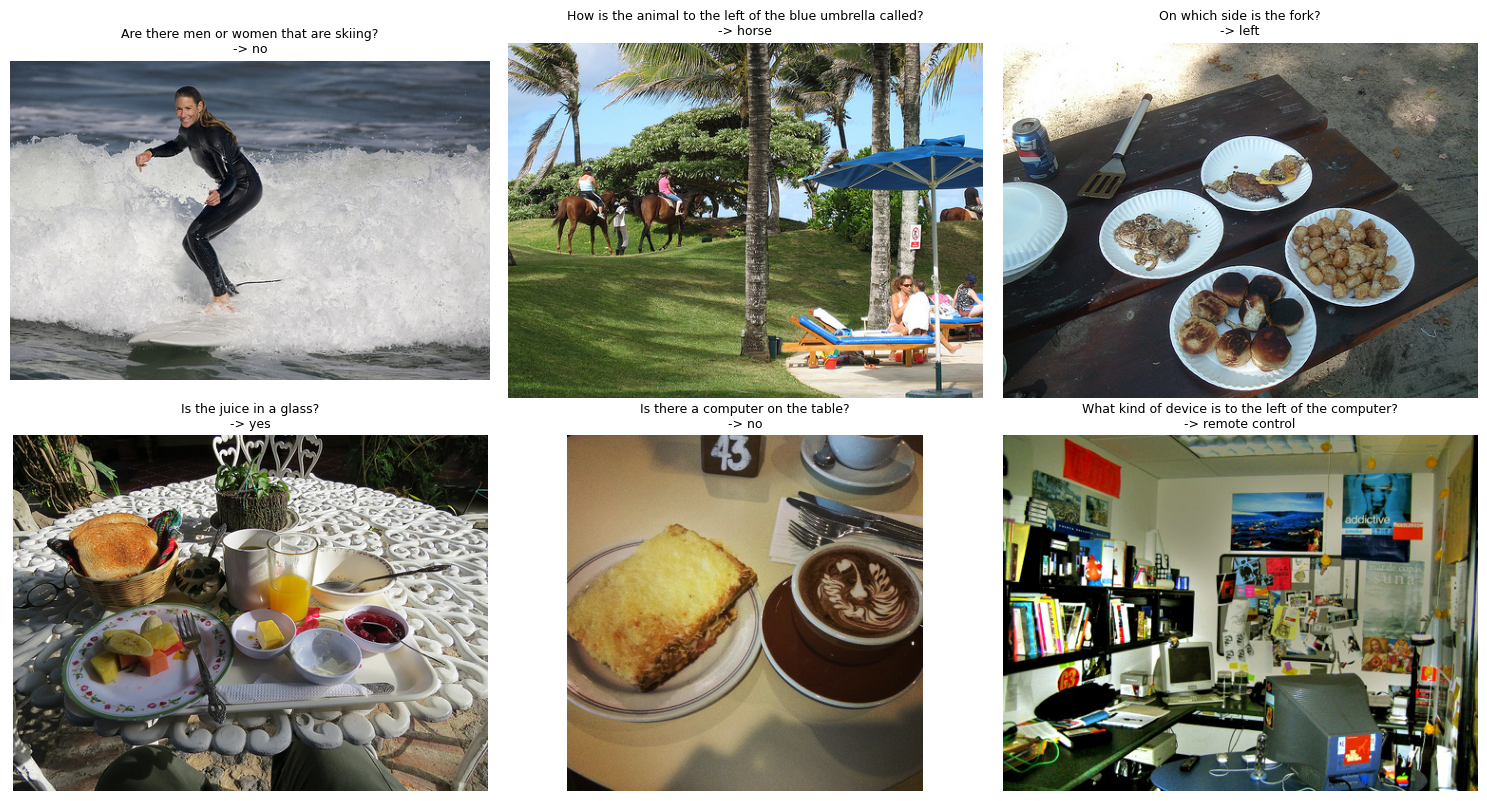

15510572 (375, 500) ems? Answer the question using a single word or phrase. -> jeans
15510575 (375, 500) lue? Answer the question using a single word or phrase. -> jeans
15510596 (375, 500) top? Answer the question using a single word or phrase. -> top
15510600 (375, 500) ans? Answer the question using a single word or phrase. -> man
Evaluator on gold answers (must be 1.0): 1.0
Packed example: [
 {
  "from": "human",
  "value": "<image>\nThe person that is to the right of the crate is wearing what?\nAnswer the question using a single word or phrase."
 },
 {
  "from": "gpt",
  "value": "gloves"
 },
 {
  "from": "human",
  "value": "How old is the person that is wearing gloves?\nAnswer the question using a single word or phrase."
 },
 {
  "from": "gpt",
  "value": "young"
 }
]


In [11]:
# visual check: image + prompt + answer
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, r in zip(axes.ravel(), random.Random(SEED).sample(tr, 6)):
    ax.imshow(Image.open(OUT / r["image"]).convert("RGB")); ax.axis("off")
    ax.set_title(f"{r['conversations'][0]['value'].split(chr(10))[1]}\n-> {r['conversations'][1]['value']}", fontsize=9)
plt.tight_layout(); plt.show()

# dataloader + evaluator smoke test (uses the helper module that later notebooks will import)
sys.path.insert(0, str(OUT)); import importlib, gqa_utils; importlib.reload(gqa_utils)
from torch.utils.data import DataLoader
ds = gqa_utils.GQADataset(OUT / "dev_mini.json")
batch = next(iter(DataLoader(ds, batch_size=4, collate_fn=lambda b: b, num_workers=2)))
for b in batch: print(b["id"], b["image"].size, b["conversations"][0]["value"][-55:].replace("\n", " "), "->", b["conversations"][1]["value"])
oracle = {r["id"]: r["conversations"][1]["value"] for r in dmini}
print("Evaluator on gold answers (must be 1.0):", gqa_utils.evaluate(oracle, dmini)["all"])
print("Packed example:", json.dumps(load_rows(f"train_{CFG['train_tiers'][0]}_packed")[0]["conversations"][:4], indent=1))

## 11. Freeze: stats and README

In [12]:
stats = dict(version=CFG["version"], seed=SEED, config=CFG, counts=COUNTS, raw_report=REPORT, tier_representativeness=REP,
             bad_images=sorted(BAD), structural_full_train=struct_full,
             structural_per_split={nm: dist({r["id"]: dict(structural=r["meta"]["structural"]) for r in rows}, "structural")
                                   for nm, rows in [("train_max", tr), ("dev", dev), ("testdev", test)]})
json.dump(stats, open(OUT / "stats.json", "w"), indent=2)
(OUT / "README.md").write_text(f"""# GQA sample {CFG['version']}
Source: GQA balanced questions (train / val / testdev) + GQA images. Image-level sampling, seed {SEED}.
- train_N.json: nested tiers {CFG['train_tiers']} images, single-turn. train_N_packed.json: same questions, <= {CFG['pack_turns']} turns per record.
- dev.json / dev_mini.json: val_balanced ({CFG['dev_images']} / {CFG['dev_mini_images']} images). testdev.json: full testdev_balanced (do not tune on it).
- Prompt suffix (training AND evaluation): {CFG['suffix']!r}
- gqa_utils.py: GQADataset, normalize, evaluate (per-type accuracy, invalid-output rate).
""")
total = sum(p.stat().st_size for p in OUT.rglob("*") if p.is_file()) / 1e9
print(f"Output: {OUT} ({total:.2f} GB)")

Output: /kaggle/working/gqa_v2_seed42 (3.32 GB)


## 12. Save as a Kaggle Dataset
1. **Save Version -> Save & Run All (Commit)**.
2. Open the finished version -> **Output** tab -> **New Dataset** -> name it `gqa-sample-v2-seed42`.
3. In later notebooks attach it and read from `/kaggle/input/gqa-sample-v2-seed42/`.

If you change the seed, tiers or suffix, make a `v3` instead of overwriting.